# 01 · Data quality log and data quality report

**Phase 1 deliverables:** the data quality log (every check, what it found, the fix and its status after cleaning) and the **data quality report** in Word.

Everything here is read from your PostgreSQL database, so it reflects the SQL you ran in Week 1:

| Comes from | SQL file |
|---|---|
| `dq.dq_log` (62 checks on the raw tables) | `week1/2_data_quality_audit.sql` |
| `dq.recheck_after_cleaning`, `clean.*` tables, merge map, look-alike queue (STEP 11) | `week1/3_cleaning_and_baselines.sql` |

**Outputs** (folder `reports/01_data_quality/`): `data_quality_log.csv`, `data_quality_log.xlsx`, `Veltrix_data_quality_report.docx` and the charts.

Run the cells from top to bottom (Kernel > Restart & Run All). The password is asked for once and never stored.

In [1]:
# First time only: install the packages the notebooks use (then restart the kernel)
# %pip install sqlalchemy psycopg2-binary python-docx python-pptx openpyxl seaborn kmodes
%pip install sqlalchemy psycopg2-binary python-docx python-pptx openpyxl seaborn kmodes scikit-learn scipy pyarrow mlflow


   ---------------------------------------- 0/4 [XlsxWriter]
   ---------- ----------------------------- 1/4 [python-docx]
   ---------- ----------------------------- 1/4 [python-docx]
   -------------------- ------------------- 2/4 [python-pptx]
   -------------------- ------------------- 2/4 [python-pptx]
   ------------------------------ --------- 3/4 [kmodes]
   ---------------------------------------- 4/4 [kmodes]

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import vx

vx.connect()          # localhost, database veltrix; asks for the password
vx.style()
OUT = vx.out_dir("01_data_quality")
CH = OUT / "charts"
say = lambda s: display(Markdown(s))
pd.set_option("display.max_colwidth", 60)

Connected to database 'Veltrix' on localhost:5432 as postgres


## 1. The checks run on the raw data (`dq.dq_log`)

In [3]:
log = vx.Q("""SELECT issue_id, check_type, table_name, column_name, check_description,
                     rows_affected, rows_checked, pct_affected, severity_if_found, severity,
                     proposed_fix, dashboard_visual
              FROM dq.dq_log ORDER BY issue_id""")
found = log[log.severity != "Pass"]
say(f"**{len(log)} checks** were run on the 13 raw tables; **{len(log) - len(found)} passed** and "
    f"**{len(found)} found something** ({(found.severity == 'High').sum()} High, {(found.severity == 'Medium').sum()} Medium, "
    f"{(found.severity == 'Low').sum()} Low, {(found.severity == 'Info').sum()} Info = expected and documented).")
log.groupby(["check_type", "severity"]).size().unstack(fill_value=0)

**62 checks** were run on the 13 raw tables; **38 passed** and **24 found something** (9 High, 6 Medium, 6 Low, 3 Info = expected and documented).

severity,High,Info,Low,Medium,Pass
check_type,,,,,
Dates,0,1,0,0,7
Duplicates,2,0,0,0,0
Keys,0,0,0,0,30
Labels,2,0,0,1,0
Nulls,2,1,5,3,1
Range,3,1,1,2,0


## 2. Status after cleaning
For every issue found, the same count is re-measured on the cleaned layer (`clean.*`). The status says what was done.

In [4]:
CANON_CH = ("'Rightmove','Zoopla','OnTheMarket','Veltrix website','Google Ads','Facebook','Instagram','TikTok','WeChat',"
            "'Email newsletter','Referral','Branch walk-in','Overseas agent partner','Relocation partner'")
CANON_CO = ("'United Kingdom','Hong Kong','United Arab Emirates','China','United States','Singapore','Saudi Arabia',"
            "'India','Nigeria','Canada','Malaysia','Qatar'")
C = "clean.clean_customers"
AFTER = {   # issue_id: (status after cleaning, SQL that re-counts the problem on the clean layer)
    "DQ-31": ("Open: imputed in Phase 2 from prices viewed (notebook 04)", f"SELECT count(*) FROM {C} WHERE primary_intent='Buy' AND stated_budget_gbp IS NULL"),
    "DQ-32": ("Open: imputed in Phase 2 from rents viewed (notebook 04)", f"SELECT count(*) FROM {C} WHERE primary_intent='Rent' AND stated_rent_budget_pcm_gbp IS NULL"),
    "DQ-33": ("Accepted: kept as 'Unknown' (filled from duplicates where possible)", f"SELECT count(*) FROM {C} WHERE age_band IS NULL"),
    "DQ-34": ("Accepted: kept as 'Unknown' (filled from duplicates where possible)", f"SELECT count(*) FROM {C} WHERE occupation_sector IS NULL"),
    "DQ-35": ("Fixed in clean layer", f"SELECT count(*) FROM {C} WHERE gender IS NULL"),
    "DQ-37": ("Accepted: match on email and profile instead", f"SELECT count(*) FROM {C} WHERE phone_sha256 IS NULL"),
    "DQ-38": ("Handled in KPIs: 'Unknown' reply band, excluded from medians", "SELECT count(*) FROM clean.clean_interactions WHERE direction='Inbound' AND response_time_min IS NULL"),
    "DQ-39": ("Accepted: not used by the dashboard KPIs", "SELECT count(*) FROM clean.clean_properties WHERE size_sqm IS NULL"),
    "DQ-40": ("Accepted: kept as 'Unknown'", "SELECT count(*) FROM clean.clean_properties WHERE epc_rating IS NULL"),
    "DQ-41": ("Fixed in clean layer (set to 'Renting')", "SELECT count(*) FROM clean.clean_transactions WHERE finance_type IS NULL"),
    "DQ-42": ("Expected: used for traffic totals only", "SELECT count(*) FROM clean.clean_web_sessions WHERE customer_id IS NULL"),
    "DQ-43": ("Fixed in clean layer (CASE mapping, 14 channels)", f"SELECT count(*) FROM clean.clean_leads WHERE lead_source NOT IN ({CANON_CH})"),
    "DQ-44": ("Fixed in clean layer (CASE mapping, 12 countries + ISO)", f"SELECT count(*) FROM {C} WHERE country_of_residence NOT IN ({CANON_CO})"),
    "DQ-45": ("Rule: overseas = residence, never IP address", "SELECT count(*) FROM clean.clean_web_sessions w JOIN clean.clean_customers c USING (customer_id) WHERE w.ip_country <> 'GB' AND NOT c.is_overseas"),
    "DQ-46": ("Fixed in clean layer (x1000)", f"SELECT count(*) FROM {C} WHERE stated_budget_gbp < 5000"),
    "DQ-47": ("Fixed in clean layer (/10)", f"SELECT count(*) FROM {C} c JOIN dq.customer_viewed_prices v USING (customer_id) WHERE v.n_sale_views >= 3 AND c.stated_budget_gbp >= 6 * v.med_viewed_price"),
    "DQ-48": ("Fixed in clean layer (first digit dropped)", f"SELECT count(*) FROM {C} c JOIN dq.customer_viewed_prices v USING (customer_id) WHERE v.n_sale_views >= 3 AND c.stated_budget_gbp BETWEEN 3 * v.med_viewed_price AND 6 * v.med_viewed_price AND c.stated_budget_gbp::bigint::text LIKE '1%' AND (c.stated_budget_gbp - power(10, length(c.stated_budget_gbp::bigint::text) - 1)) / v.med_viewed_price BETWEEN 0.6 AND 1.6"),
    "DQ-49": ("Fixed in clean layer (/12 or /10)", f"SELECT count(*) FROM {C} WHERE stated_rent_budget_pcm_gbp >= 10000"),
    "DQ-50": ("Open: confirm with finance; excluded from payments-due totals", "SELECT count(*) FROM clean.clean_payments WHERE amount_gbp < 0"),
    "DQ-51": ("Expected: kept (competitive bids)", "SELECT count(*) FROM clean.clean_transactions WHERE discount_pct < 0"),
    "DQ-52": ("Handled in KPIs: reply bands and medians, never means", "SELECT count(*) FROM clean.clean_interactions WHERE response_time_min = 4320"),
    "DQ-60": ("Expected: excluded from the late-payment share", "SELECT count(*) FROM clean.clean_payments WHERE due_date > DATE '2026-09-30'"),
    "DQ-61": ("Fixed in clean layer (merged to the oldest record)", "SELECT count(*) FROM (SELECT count(*) OVER (PARTITION BY email_sha256) AS n FROM clean.clean_customers) x WHERE n > 1"),
    "DQ-62": ("Fixed in clean layer (merged to the oldest record)", "SELECT count(*) FROM (SELECT phone_sha256, count(*) OVER (PARTITION BY phone_sha256) AS n FROM clean.clean_customers) x WHERE n > 1 AND phone_sha256 IS NOT NULL"),
}

def after(row):
    if row.severity == "Pass":
        return pd.Series({"rows_after_cleaning": 0, "status": "Pass"})
    status, sql = AFTER.get(row.issue_id, ("Open: review", None))
    return pd.Series({"rows_after_cleaning": vx.V(sql) if sql else row.rows_affected, "status": status})

log[["rows_after_cleaning", "status"]] = log.apply(after, axis=1)
log.loc[log.severity != "Pass", ["issue_id", "table_name", "check_description", "rows_affected", "rows_after_cleaning", "status"]]

,issue_id,table_name,check_description,rows_affected,rows_after_cleaning,status
30,DQ-31,customers,Buyer with no purchase budget,30796,30138,Open: imputed in Phase 2 from prices viewed (notebook 04)
31,DQ-32,customers,Renter with no rent budget,8129,8009,Open: imputed in Phase 2 from rents viewed (notebook 04)
32,DQ-33,customers,age_band missing,28096,27287,Accepted: kept as 'Unknown' (filled from duplicates wher...
33,DQ-34,customers,occupation_sector missing,27378,27000,Accepted: kept as 'Unknown' (filled from duplicates wher...
34,DQ-35,customers,gender blank AND a separate Not stated value,11156,0,Fixed in clean layer
36,DQ-37,customers,No phone (limits duplicate matching),28918,28440,Accepted: match on email and profile instead
37,DQ-38,interactions,Inbound contact with no reply time,5830,5830,"Handled in KPIs: 'Unknown' reply band, excluded from med..."
38,DQ-39,properties,size_sqm missing,671,671,Accepted: not used by the dashboard KPIs
39,DQ-40,properties,epc_rating missing,1193,1193,Accepted: kept as 'Unknown'
40,DQ-41,transactions,Tenancy with no finance_type,3327,0,Fixed in clean layer (set to 'Renting')


## 3. Duplicates: the look-alike review queue and (project lead only) the score against `duplicate_of`

In [5]:
mm = vx.Q("SELECT customer_id, master_customer_id, is_master, matched_on FROM clean.customer_merge_map")
merged = mm[~mm.is_master]
by_rule = merged.matched_on.value_counts()
queue = vx.Q("SELECT * FROM clean.dedupe_review_queue ORDER BY queue_rank") if vx.exists("clean.dedupe_review_queue") else pd.DataFrame()
say(f"Automatic merge on shared email or phone hash: **{len(mm):,} records → {mm.is_master.sum():,} customers** "
    f"({len(merged):,} merged: {by_rule.get('same email', 0):,} on email, {by_rule.get('same phone', 0):,} on phone). "
    + (f"Look-alike queue: **{len(queue):,} pairs** waiting for manual review "
       f"(match weight {queue.match_weight.min():.1f} to {queue.match_weight.max():.1f})." if len(queue) else
       "Look-alike queue not built yet: run STEP 11 of `3_cleaning_and_baselines.sql`."))

new_rows = []
if len(queue):
    new_rows.append(dict(issue_id="DQ-63", check_type="Duplicates", table_name="customers", column_name="(profile)",
        check_description="Profile look-alike pairs (no shared hash) queued for manual review",
        rows_affected=len(queue), rows_checked=int(mm.is_master.sum()), pct_affected=round(100 * len(queue) / mm.is_master.sum(), 2),
        severity_if_found="Medium", severity="Medium", proposed_fix="Reviewers work clean.dedupe_review_queue from rank 1; accepted pairs join the merge map",
        dashboard_visual="Overview: customers card", rows_after_cleaning=int((queue.review_decision == "pending").sum()),
        status="Open: manual review (top 100 first)"))

Automatic merge on shared email or phone hash: **102,000 records → 100,573 customers** (1,427 merged: 904 on email, 523 on phone). Look-alike queue: **1,000 pairs** waiting for manual review (match weight 15.8 to 19.1).

In [6]:
# PROJECT LEAD ONLY: reads ONLY customer_id and duplicate_of from the answer key (never true_persona).
PROJECT_LEAD = vx.ANSWER_KEY.exists()
score = None
if PROJECT_LEAD:
    key = pd.read_parquet(vx.ANSWER_KEY, columns=["customer_id", "duplicate_of"])
    key["true_root"] = key.duplicate_of.fillna(key.customer_id)
    root = key.set_index("customer_id").true_root
    j = mm.assign(true_root=mm.customer_id.map(root), master_true_root=mm.master_customer_id.map(root))
    true_dups = int(key.duplicate_of.notna().sum())
    correct = int(((~j.is_master) & (j.true_root == j.master_true_root)).sum())
    master_of = mm.set_index("customer_id").master_customer_id
    leads = vx.Q("""SELECT lead_id, customer_id, lead_stage IN ('New','Contacted','Qualified','Viewing','Offer') AS active FROM raw.leads""")
    leads["matched"] = leads.customer_id.map(master_of) == leads.customer_id.map(root).map(master_of)
    leads["before"] = leads.customer_id.map(root) == leads.customer_id
    gate = leads.groupby("active")[["before", "matched"]].mean().mul(100).round(2)
    q_prec = None
    if len(queue):
        qq = queue.assign(true=queue.customer_id_a.map(root) == queue.customer_id_b.map(root))
        qq["band"] = pd.cut(qq.queue_rank, [0, 100, 250, 500, 1000], labels=["1-100", "101-250", "251-500", "501-1000"])
        q_prec = qq.groupby("band", observed=True).true.agg(["size", "sum"]).rename(columns={"size": "pairs", "sum": "true_pairs"})
        q_prec["precision_pct"] = (100 * q_prec.true_pairs / q_prec.pairs).round(1)
    active_after = gate.loc[True, "matched"]
    score = dict(true_dups=true_dups, merged=len(merged), correct=correct, false=len(merged) - correct,
                 precision=100 * correct / len(merged), recall=100 * correct / true_dups,
                 active_before=gate.loc[True, "before"], active_after=active_after,
                 all_after=100 * leads.matched.mean(), gate="PASS" if active_after >= 95 else "FAIL", queue=q_prec)
    say(f"**Scored against `duplicate_of`:** {true_dups:,} true duplicates; {len(merged):,} merged, of which **{correct:,} correct** "
        f"(precision **{score['precision']:.1f}%**, recall **{score['recall'] + 1e-9:.1f}%**). "
        f"**Gate:** active leads matched to one customer ID **{score['active_before']:.1f}% → {active_after:.1f}%** "
        f"(target 95%): **{score['gate']}**.")
    new_rows.append(dict(issue_id="DQ-64", check_type="Gate", table_name="leads", column_name="customer_id",
        check_description="Active leads matched to one customer ID (Phase 1 gate: 95% or more)",
        rows_affected=int((leads.active & ~leads.matched).sum()), rows_checked=int(leads.active.sum()),
        pct_affected=round(100 - active_after, 2), severity_if_found="High", severity="Pass" if score["gate"] == "PASS" else "High",
        proposed_fix="Merge on email/phone + manual review of look-alikes", dashboard_visual="All pages",
        rows_after_cleaning=int((leads.active & ~leads.matched).sum()), status=f"{score['gate']}: {active_after:.1f}% matched"))
    display(q_prec)
else:
    say("Answer key not found, so the scoring step is skipped (only the project lead holds it). "
        "The project lead can run STEP 12 of `3_cleaning_and_baselines.sql` instead.")

log = pd.concat([log, pd.DataFrame(new_rows)], ignore_index=True)

Answer key not found, so the scoring step is skipped (only the project lead holds it). The project lead can run STEP 12 of `3_cleaning_and_baselines.sql` instead.

## 4. Save the data quality log (CSV and Excel)

In [7]:
cols = ["issue_id", "check_type", "table_name", "column_name", "check_description", "rows_affected", "rows_checked",
        "pct_affected", "severity", "proposed_fix", "dashboard_visual", "rows_after_cleaning", "status"]
log = log[cols]
log.to_csv(OUT / "data_quality_log.csv", index=False)
with pd.ExcelWriter(OUT / "data_quality_log.xlsx", engine="openpyxl") as xw:
    log.to_excel(xw, sheet_name="dq_log", index=False)
    ws = xw.sheets["dq_log"]
    for col, w in zip("ABCDEFGHIJKLM", [9, 11, 15, 22, 55, 13, 13, 11, 10, 45, 32, 16, 45]):
        ws.column_dimensions[col].width = w
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
print("Saved data_quality_log.csv and .xlsx:", len(log), "checks")

Saved data_quality_log.csv and .xlsx: 63 checks


## 5. Charts for the report

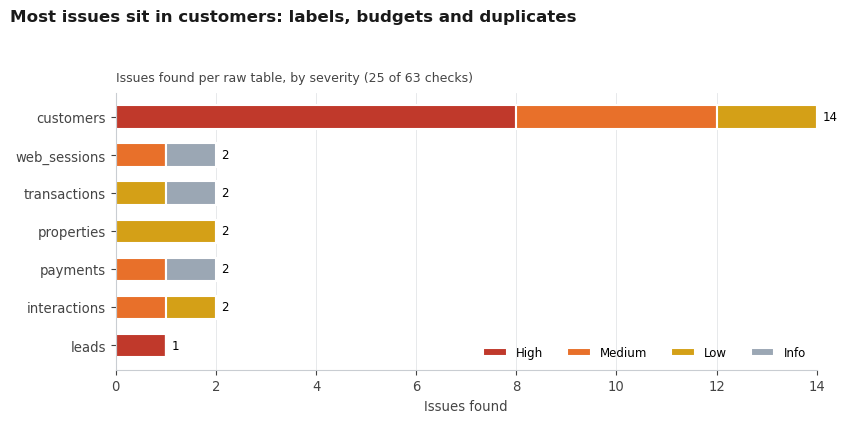

In [8]:
SEV = {"High": "#C0392B", "Medium": "#E8702A", "Low": "#D4A017", "Info": vx.GREY}
iss = log[~log.severity.isin(["Pass"])]
t = iss.groupby(["table_name", "severity"]).size().unstack(fill_value=0).reindex(columns=list(SEV), fill_value=0)
t = t.loc[t.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
left = pd.Series(0, index=t.index)
for s in SEV:
    ax.barh(t.index, t[s], left=left, color=SEV[s], label=s, height=0.62, edgecolor="white", linewidth=1.5)
    left += t[s]
for i, v in enumerate(left):
    ax.annotate(str(int(v)), (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5)
ax.legend(ncol=4, loc="lower right")
ax.grid(axis="y", visible=False)
top_table = t.sum(axis=1).idxmax()
p1 = vx.finish(fig, ax, f"Most issues sit in {top_table}: labels, budgets and duplicates",
               f"Issues found per raw table, by severity ({len(iss)} of {len(log)} checks)", CH / "dq_issues_by_table.png",
               xlabel="Issues found")

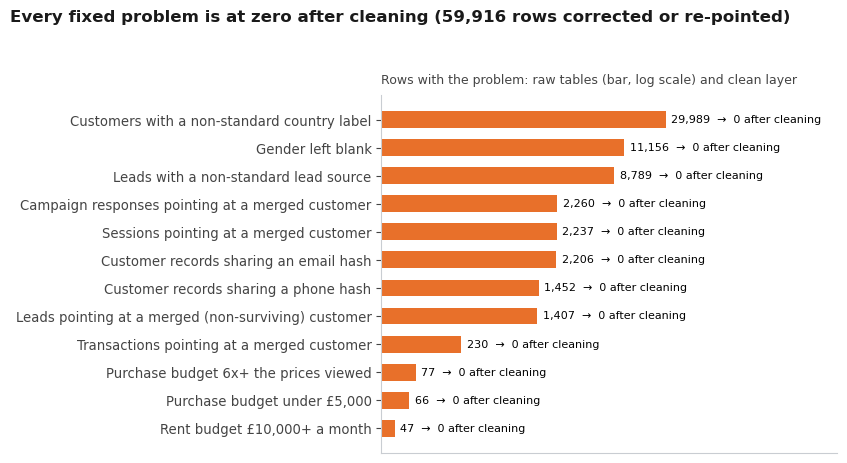

In [9]:
rc = vx.Q("SELECT check_name, raw_rows, clean_rows FROM dq.recheck_after_cleaning").sort_values("raw_rows")
fig, ax = plt.subplots(figsize=(8.5, 4.6))
b = ax.barh(rc.check_name, rc.raw_rows, color=vx.ORANGE, height=0.6, label="Raw")
for bar, c in zip(b, rc.clean_rows):
    ax.annotate(f"{bar.get_width():,.0f}  →  {c:,} after cleaning", (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlim(right=rc.raw_rows.max() * 60)
ax.set_xticks([])
ax.minorticks_off()
ax.grid(axis="y", visible=False)
p2 = vx.finish(fig, ax, f"Every fixed problem is at zero after cleaning ({rc.raw_rows.sum():,} rows corrected or re-pointed)",
               "Rows with the problem: raw tables (bar, log scale) and clean layer", CH / "dq_before_after.png")

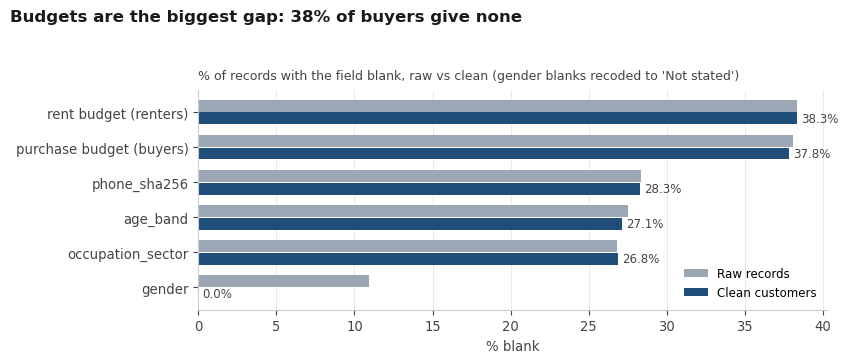

In [10]:
miss = vx.Q("""SELECT 'age_band' col, avg((age_band IS NULL)::int) raw FROM raw.customers
 UNION ALL SELECT 'occupation_sector', avg((occupation_sector IS NULL)::int) FROM raw.customers
 UNION ALL SELECT 'phone_sha256', avg((phone_sha256 IS NULL)::int) FROM raw.customers
 UNION ALL SELECT 'gender', avg((gender IS NULL)::int) FROM raw.customers
 UNION ALL SELECT 'purchase budget (buyers)', avg((stated_budget_gbp IS NULL)::int) FROM raw.customers WHERE primary_intent='Buy'
 UNION ALL SELECT 'rent budget (renters)', avg((stated_rent_budget_pcm_gbp IS NULL)::int) FROM raw.customers WHERE primary_intent='Rent'""")
miss_c = vx.Q("""SELECT 'age_band' col, avg((age_band IS NULL)::int) clean FROM clean.clean_customers
 UNION ALL SELECT 'occupation_sector', avg((occupation_sector IS NULL)::int) FROM clean.clean_customers
 UNION ALL SELECT 'phone_sha256', avg((phone_sha256 IS NULL)::int) FROM clean.clean_customers
 UNION ALL SELECT 'gender', avg((gender IS NULL)::int) FROM clean.clean_customers
 UNION ALL SELECT 'purchase budget (buyers)', avg((stated_budget_gbp IS NULL)::int) FROM clean.clean_customers WHERE primary_intent='Buy'
 UNION ALL SELECT 'rent budget (renters)', avg((stated_rent_budget_pcm_gbp IS NULL)::int) FROM clean.clean_customers WHERE primary_intent='Rent'""")
mc = miss.merge(miss_c, on="col").set_index("col").mul(100).sort_values("raw")
fig, ax = plt.subplots(figsize=(8.5, 3.6))
y = range(len(mc))
ax.barh([i + 0.18 for i in y], mc.raw, height=0.34, color=vx.GREY, label="Raw records")
bb = ax.barh([i - 0.18 for i in y], mc.clean, height=0.34, color=vx.NAVY, label="Clean customers")
ax.set_yticks(list(y), mc.index)
vx.barh_labels(ax, bb, "{:.1f}%")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
p3 = vx.finish(fig, ax, f"Budgets are the biggest gap: {mc.loc['purchase budget (buyers)', 'clean']:.0f}% of buyers give none",
               "% of records with the field blank, raw vs clean (gender blanks recoded to 'Not stated')", CH / "dq_missing.png",
               xlabel="% blank")

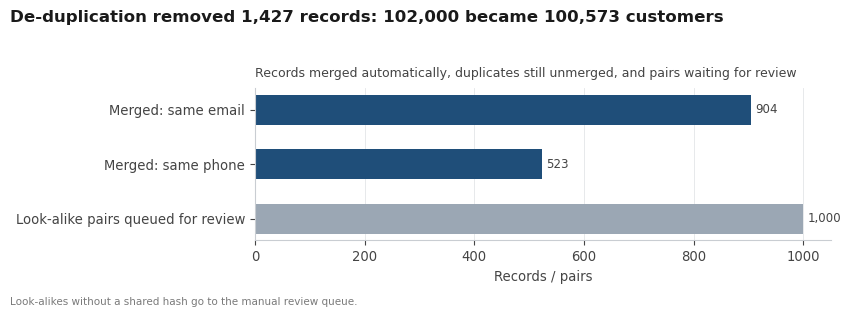

In [11]:
bars = [("Merged: same email", by_rule.get("same email", 0), vx.NAVY), ("Merged: same phone", by_rule.get("same phone", 0), vx.NAVY)]
if score:
    bars.append(("True duplicates still unmerged", score["true_dups"] - score["correct"], vx.ORANGE))
if len(queue):
    bars.append(("Look-alike pairs queued for review", len(queue), vx.GREY))
fig, ax = plt.subplots(figsize=(8.5, 3.0))
bb = ax.barh([b[0] for b in bars][::-1], [b[1] for b in bars][::-1], color=[b[2] for b in bars][::-1], height=0.55)
vx.barh_labels(ax, bb)
ax.grid(axis="y", visible=False)
note = (f"Answer key (project lead only): {score['true_dups']:,} true duplicates in the data." if score
        else "Look-alikes without a shared hash go to the manual review queue.")
p4 = vx.finish(fig, ax, f"De-duplication removed {len(merged):,} records: {len(mm):,} became {mm.is_master.sum():,} customers",
               "Records merged automatically, duplicates still unmerged, and pairs waiting for review", CH / "dq_dedupe.png",
               note=note, xlabel="Records / pairs")

## 6. The data quality report (Word)

In [12]:
fixed = log.status.str.startswith("Fixed").sum()
open_ = log.status.str.startswith("Open").sum()
acc = log.status.str.match("^(Accepted|Handled|Expected|Rule)").sum()
r = vx.Report("Data quality report", "Phase 1 · Data audit and assembly",
              f"Source: PostgreSQL database, schemas raw, dq and clean · data to 30 Sep 2026 · generated by notebooks/01_data_quality.ipynb")
r.h1("1. Summary")
r.kpis([(f"{len(log)}", "checks run"), (f"{len(iss)}", "issues found"), (f"{fixed}", "fixed in the clean layer"),
        (f"{acc}", "accepted or handled in KPIs"), (f"{open_}", "still open")])
r.p(f"We checked every one of the 13 raw tables for broken keys, missing values, inconsistent labels, impossible ranges, "
    f"date order and duplicates. **{len(log) - len(iss)} checks passed.** The **{len(iss)} issues** found are listed in the "
    f"data quality log (`data_quality_log.xlsx`) with the rows affected, the fix, the dashboard visual each would distort and "
    f"the count after cleaning.")
bul = [f"**Keys and dates are sound.** Every primary key is unique and every foreign key resolves; no lead closes before it opens and no viewing precedes its lead.",
       f"**Labels were fixed with mapping tables.** {vx.n(log.set_index('issue_id').loc['DQ-43', 'rows_affected'])} leads used one of 28 spellings of 14 channels, and "
       f"{vx.n(log.set_index('issue_id').loc['DQ-44', 'rows_affected'])} customers one of 26 labels for 12 countries. Both are now standard.",
       f"**Budget typos were corrected** (£k entries, extra zeros, stray leading 1, annual rents): {vx.n(vx.V('SELECT count(*) FROM clean.budget_fixes'))} values, each logged with its rule in `clean.budget_fixes`.",
       f"**Duplicates were merged.** {vx.n(len(mm))} records became {vx.n(mm.is_master.sum())} customers; their leads, sessions, responses and deals were re-pointed to the surviving ID."]
if score:
    bul.append(f"**Phase 1 gate passed:** {score['active_after']:.1f}% of active leads are matched to one customer ID (target 95%). "
               f"The automatic merge made {score['false']} false merges (precision {score['precision']:.0f}%).")
bul.append(f"**Missing budgets are the main open item:** {mc.loc['purchase budget (buyers)', 'clean']:.0f}% of buyers and "
           f"{mc.loc['rent budget (renters)', 'clean']:.0f}% of renters give none. Phase 2 estimates them from the prices each customer viewed.")
r.bullets(bul)
if score:
    r.callout(f"**Recommendation:** accept the cleaned database for Phase 2. The gate is met ({score['active_after']:.1f}% ≥ 95%), "
              f"every High issue is fixed or handled, and the remaining duplicates sit in a ranked review queue.")
else:
    r.callout("**Recommendation:** accept the cleaned database for Phase 2 once the project lead confirms the 95% gate "
              "(STEP 12 of 3_cleaning_and_baselines.sql); every High issue is fixed or handled.")

r.h1("2. How the audit was done")
r.p("Each check is one SQL query on the raw tables (file 2_data_quality_audit.sql). The raw tables are never edited: every fix "
    "lives in a mapping table or in the clean layer (file 3_cleaning_and_baselines.sql), so it can be audited and re-run monthly. "
    "After cleaning, the same problems were re-counted on the clean tables.")
r.table(log.groupby("check_type").agg(checks=("issue_id", "size"), issues_found=("severity", lambda s: (s != "Pass").sum()),
        rows_affected=("rows_affected", "sum")).reset_index().rename(columns={"check_type": "Check type"}),
        caption="Checks by type", widths_cm=[5, 3, 3, 4])
r.image(p1, "Issues found per raw table, by severity")

r.h1("3. Issues found and how each was handled")
show = log[log.severity != "Pass"][["issue_id", "table_name", "check_description", "rows_affected", "severity", "rows_after_cleaning", "status"]]
show.columns = ["ID", "Table", "Issue", "Rows", "Severity", "After cleaning", "Status"]
r.table(show, caption="Every issue found (full detail in data_quality_log.xlsx)", font=7.5, widths_cm=[1.3, 2.2, 5.2, 1.6, 1.5, 1.7, 4.0])
r.image(p2, "Problems fixed in the clean layer: raw count against the count after cleaning")
r.image(p3, "Missing values in the customer table, raw records vs clean customers")

r.h1("4. Duplicate customers")
r.p(f"Two records are treated as the same person when they share an email hash or a phone hash; the oldest record survives "
    f"and the newer one is merged into it ({by_rule.get('same email', 0):,} on email, {by_rule.get('same phone', 0):,} on phone). "
    f"About 45% of real duplicates share neither hash, so a second method scores profile look-alikes "
    f"(same type, intent, country and region; agreement on budget, age, occupation and buyer position, weighted by how rare each value is). "
    + (f"The **{len(queue):,} strongest pairs** are in `clean.dedupe_review_queue` for manual review; they are not merged until a reviewer accepts them." if len(queue) else ""))
r.image(p4, "Customer records before and after merging")
if score:
    r.h2("Scored against the answer key (project lead)")
    r.p(f"After the merge rules were frozen, the project lead compared them with `duplicate_of` (no other column of the key was used).")
    r.table(pd.DataFrame([["True duplicates in the data", f"{score['true_dups']:,}"], ["Records merged automatically", f"{score['merged']:,}"],
                          ["Correct merges", f"{score['correct']:,}"], ["False merges", f"{score['false']:,}"],
                          ["Precision", f"{score['precision']:.1f}%"], ["Recall", f"{score['recall'] + 1e-9:.1f}%"],
                          ["Active leads matched, before de-duplication", f"{score['active_before']:.1f}%"],
                          ["Active leads matched, after (gate 95%)", f"{score['active_after']:.1f}%  {score['gate']}"]],
                         columns=["Measure", "Result"]), caption="De-duplication scored against duplicate_of", widths_cm=[9, 5])
    if score["queue"] is not None:
        qp = score["queue"].reset_index().rename(columns={"band": "Queue ranks", "pairs": "Pairs", "true_pairs": "True duplicates", "precision_pct": "Precision %"})
        r.table(qp, caption="How many queued look-alikes are real duplicates", widths_cm=[4, 3, 3.5, 3])
        r.p(f"The top 100 pairs are the most productive ({qp.iloc[0]['Precision %']:.0f}% are real duplicates), so reviewers should start there.")

r.h1("5. Open items and how the dashboard handles them")
op = log[log.status.str.startswith("Open")][["issue_id", "check_description", "rows_after_cleaning", "status", "dashboard_visual"]]
op.columns = ["ID", "Issue", "Rows", "Next step", "Dashboard visual"]
r.table(op, caption="Open items", font=8, widths_cm=[1.3, 5.5, 1.6, 5, 3.6])
r.bullets(["**Reply times:** blank and capped values are kept out of medians and shown as an 'Unknown' band.",
           "**Overseas share:** always from country of residence, never IP address (VPNs and travel make IP unreliable).",
           "**Late payments:** payments not yet due are excluded; the latest month is flagged as still maturing.",
           "**Medians, not means,** for budgets, prices and reply times, so the few extreme values cannot move a card."])

r.h1("6. What the Power BI Data check page shows")
r.p("The dashboard has a Data check page so anyone can see the cleaning worked before trusting the other four pages:")
r.bullets(["Row counts per table, raw against the generation log (all 13 match).",
           "Issues by table and severity (the chart in section 2), from `dq.dq_log`.",
           "Raw lead-source spellings against the 14 clean channels, from `dq.raw_lead_source_chart`.",
           "A reconciliation table: every Overview card next to the same number computed in SQL (`clean.powerbi_check`)."])
r.h1("Appendix · Data quality log (all checks)")
app = log[["issue_id", "check_type", "table_name", "column_name", "check_description", "rows_affected", "severity"]]
app.columns = ["ID", "Type", "Table", "Column", "Check", "Rows", "Result"]
r.table(app, font=7, widths_cm=[1.3, 1.8, 2.3, 3.0, 5.6, 1.6, 1.4])
r.save(OUT / "Veltrix_data_quality_report.docx")

Saved reports\01_data_quality\Veltrix_data_quality_report.docx
